In [2]:
# Import libraries and define project directory
# 1. Import required libraries
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2. Define project directory
project_dir = Path(
    r"E:\DataScience\Ethereum_Monthly_TimeSeries_2015_2026"
)

# 3. Define data directories
raw_dir = project_dir / "data" / "raw"
processed_dir = project_dir / "data" / "processed"
visualizations_dir = project_dir / "visualizations"
reports_dir = project_dir / "reports"

# 4. Check project directory
print("Project:", project_dir)
print("Directory exists:", project_dir.exists())
print("Raw data directory exists:", raw_dir.exists())

Project: E:\DataScience\Ethereum_Monthly_TimeSeries_2015_2026
Directory exists: True
Raw data directory exists: True


In [3]:
# Load the BigQuery dataset
# Load monthly Ethereum transaction data from BigQuery

csv_file = raw_dir / "ethereum_monthly_txcount_full.csv"

monthly_df = pd.read_csv(csv_file)

print("Dataset loaded successfully!")
print("Rows:", len(monthly_df))
print("Columns:", monthly_df.columns.tolist())

display(monthly_df.head())

Dataset loaded successfully!
Rows: 136
Columns: ['month', 'tx_count']


,month,tx_count
0,2015-08-01,85609
1,2015-09-01,173805
2,2015-10-01,205045
3,2015-11-01,234733
4,2015-12-01,347092


In [4]:
# Validate the dataset
# Convert month column to datetime
monthly_df["month"] = pd.to_datetime(monthly_df["month"])

# Dataset validation
print("Data types:")
print(monthly_df.dtypes)

print("\nDate range:")
print("First month:", monthly_df["month"].min())
print("Last month:", monthly_df["month"].max())

print("\nMissing values:")
print(monthly_df.isna().sum())

print("\nDuplicate months:", monthly_df["month"].duplicated().sum())

print("\nTransaction count summary:")
print(monthly_df["tx_count"].describe())

Data types:
month       datetime64[us]
tx_count             int64
dtype: object

Date range:
First month: 2015-08-01 00:00:00
Last month: 2026-11-01 00:00:00

Missing values:
month       0
tx_count    0
dtype: int64

Duplicate months: 0

Transaction count summary:
count    1.360000e+02
mean     2.831723e+07
std      1.737038e+07
min      8.560900e+04
25%      1.755455e+07
50%      3.190792e+07
75%      3.673107e+07
max      7.282760e+07
Name: tx_count, dtype: float64


In [5]:
# Select complete months
# Keep complete months only
analysis_df = monthly_df[
    (monthly_df["month"] >= "2015-09-01") &
    (monthly_df["month"] <= "2026-10-01")
].copy()

analysis_df = analysis_df.set_index("month")

print("Complete monthly observations:", len(analysis_df))
print("First month:", analysis_df.index.min())
print("Last month:", analysis_df.index.max())

display(analysis_df.head())
display(analysis_df.tail())

Complete monthly observations: 134
First month: 2015-09-01 00:00:00
Last month: 2026-10-01 00:00:00


,tx_count
month,
2015-09-01,173805
2015-10-01,205045
2015-11-01,234733
2015-12-01,347092
2016-01-01,404816


,tx_count
month,
2026-06-01,63509172
2026-07-01,72368484
2026-08-01,70070530
2026-09-01,56880856
2026-10-01,55365081


In [6]:
# Save the cleaned dataset
# Save cleaned monthly dataset

output_file = processed_dir / "ethereum_monthly_txcount_2015_2026.csv"

analysis_df.to_csv(output_file)

print("Cleaned dataset saved successfully!")
print("File:", output_file)
print("Observations:", len(analysis_df))

Cleaned dataset saved successfully!
File: E:\DataScience\Ethereum_Monthly_TimeSeries_2015_2026\data\processed\ethereum_monthly_txcount_2015_2026.csv
Observations: 134


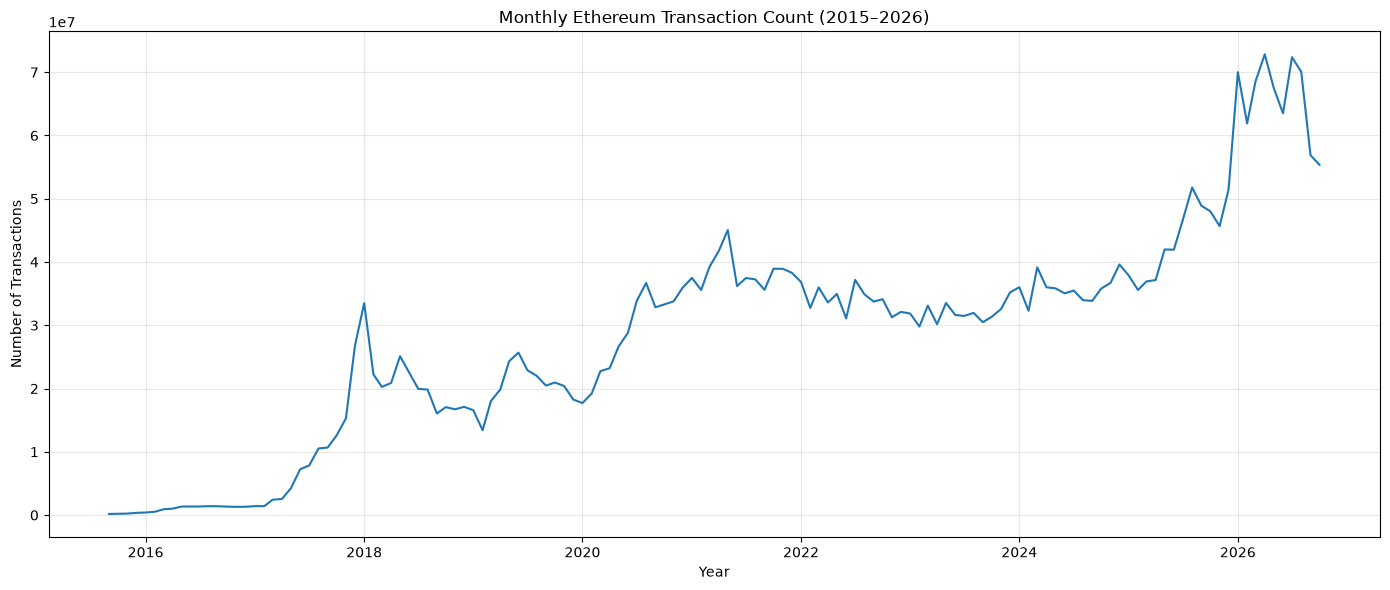

Chart saved: E:\DataScience\Ethereum_Monthly_TimeSeries_2015_2026\visualizations\01_monthly_transaction_count.png


In [7]:
# Plot monthly Ethereum transactions
# Monthly Ethereum transaction count: 2015–2026

plt.figure(figsize=(14, 6))

plt.plot(
    analysis_df.index,
    analysis_df["tx_count"],
    linewidth=1.5
)

plt.title("Monthly Ethereum Transaction Count (2015–2026)")
plt.xlabel("Year")
plt.ylabel("Number of Transactions")
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save visualization
chart_file = visualizations_dir / "01_monthly_transaction_count.png"
plt.savefig(chart_file, dpi=300, bbox_inches="tight")

plt.show()

print("Chart saved:", chart_file)

In [8]:
# Descriptive statistics
# Descriptive statistics of monthly Ethereum transactions

print("DESCRIPTIVE STATISTICS")
print("=" * 45)

print(analysis_df["tx_count"].describe().round(2))

print("\nAdditional statistics")
print("=" * 45)

print("Total transactions:",
      f"{analysis_df['tx_count'].sum():,}")

print("Median:",
      f"{analysis_df['tx_count'].median():,.0f}")

print("Standard deviation:",
      f"{analysis_df['tx_count'].std():,.0f}")

print("Minimum month:",
      analysis_df["tx_count"].idxmin().strftime("%B %Y"))

print("Maximum month:",
      analysis_df["tx_count"].idxmax().strftime("%B %Y"))

DESCRIPTIVE STATISTICS
count         134.00
mean     28525702.87
std      17327152.93
min        173805.00
25%      17785047.50
50%      32034452.00
75%      36811107.50
max      72827602.00
Name: tx_count, dtype: float64

Additional statistics
Total transactions: 3,822,444,185
Median: 32,034,452
Standard deviation: 17,327,153
Minimum month: September 2015
Maximum month: April 2026


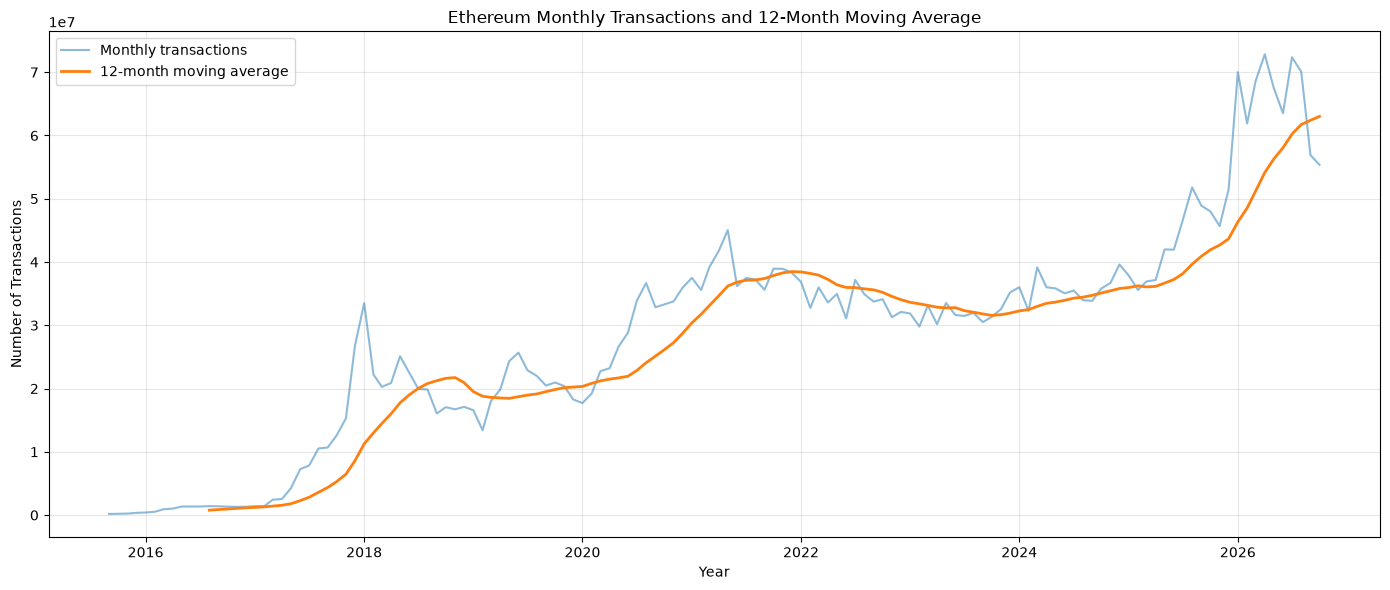

In [9]:
# # Calculate 12-month rolling average

analysis_df["rolling_12m"] = (
    analysis_df["tx_count"].rolling(window=12).mean()
)

# Plot monthly transactions and rolling average

plt.figure(figsize=(14, 6))

plt.plot(
    analysis_df.index,
    analysis_df["tx_count"],
    label="Monthly transactions",
    alpha=0.5
)

plt.plot(
    analysis_df.index,
    analysis_df["rolling_12m"],
    label="12-month moving average",
    linewidth=2
)

plt.title("Ethereum Monthly Transactions and 12-Month Moving Average")
plt.xlabel("Year")
plt.ylabel("Number of Transactions")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

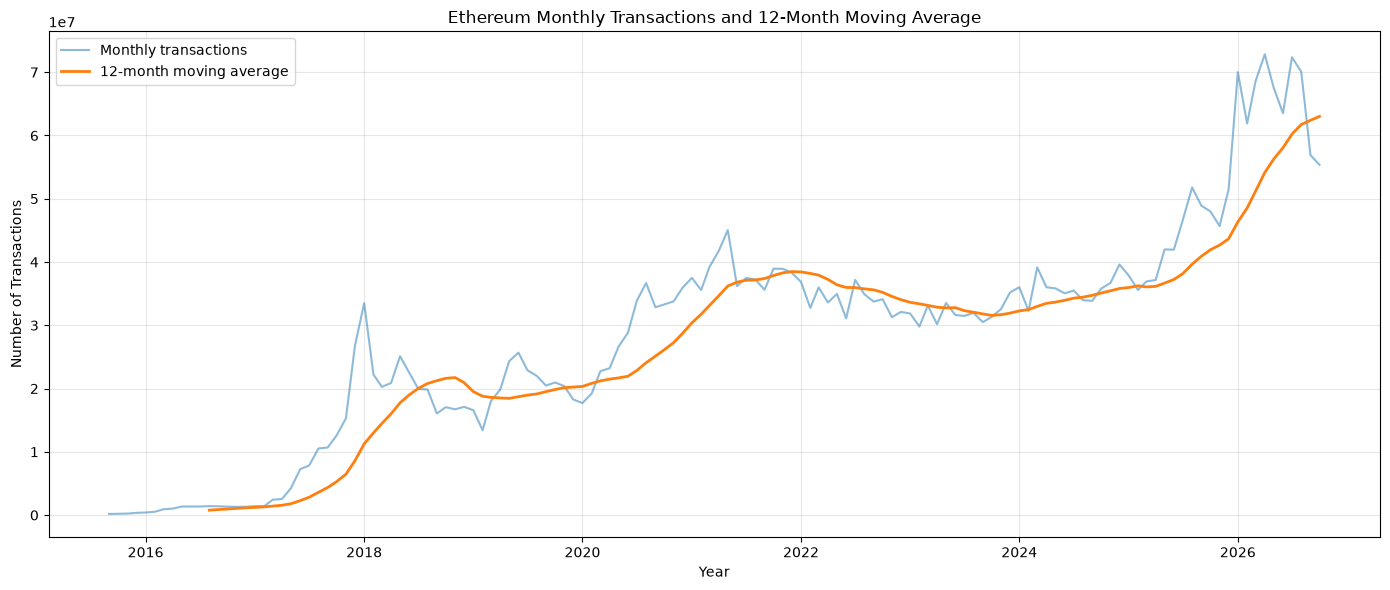

Chart saved: E:\DataScience\Ethereum_Monthly_TimeSeries_2015_2026\visualizations\02_monthly_transactions_12m_moving_average.png


In [10]:
# Save the moving-average visualization

chart_file = visualizations_dir / "02_monthly_transactions_12m_moving_average.png"

plt.figure(figsize=(14, 6))

plt.plot(analysis_df.index, analysis_df["tx_count"],
         label="Monthly transactions", alpha=0.5)

plt.plot(analysis_df.index, analysis_df["rolling_12m"],
         label="12-month moving average", linewidth=2)

plt.title("Ethereum Monthly Transactions and 12-Month Moving Average")
plt.xlabel("Year")
plt.ylabel("Number of Transactions")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_file)

In [11]:
# Calculate year-over-year growth
# Calculate year-over-year transaction growth (%)

analysis_df["yoy_growth_pct"] = (
    analysis_df["tx_count"].pct_change(periods=12) * 100
)

print("Year-over-year growth statistics")
print("=" * 45)

print(analysis_df["yoy_growth_pct"].describe().round(2))

Year-over-year growth statistics
count     122.00
mean      139.62
std       347.95
min       -50.54
25%         3.43
50%        17.10
75%        78.41
max      2276.76
Name: yoy_growth_pct, dtype: float64


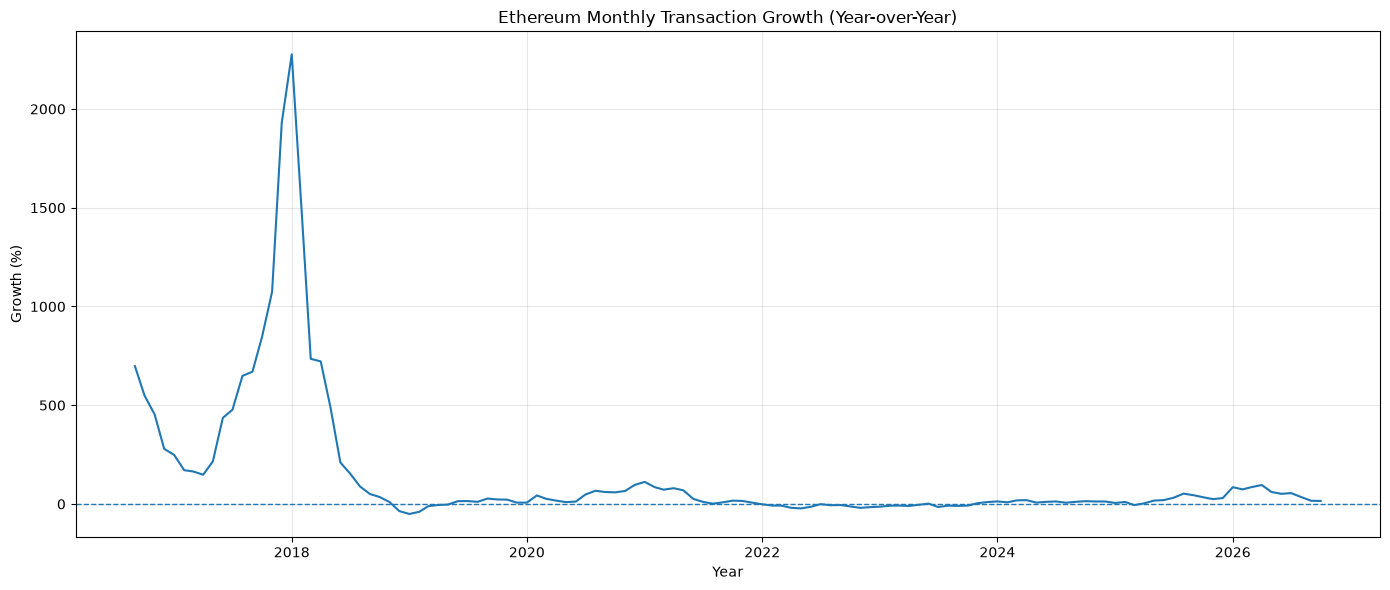

In [12]:
# Plot year-over-year transaction growth

plt.figure(figsize=(14, 6))

plt.plot(
    analysis_df.index,
    analysis_df["yoy_growth_pct"],
    linewidth=1.5
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title("Ethereum Monthly Transaction Growth (Year-over-Year)")
plt.xlabel("Year")
plt.ylabel("Growth (%)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

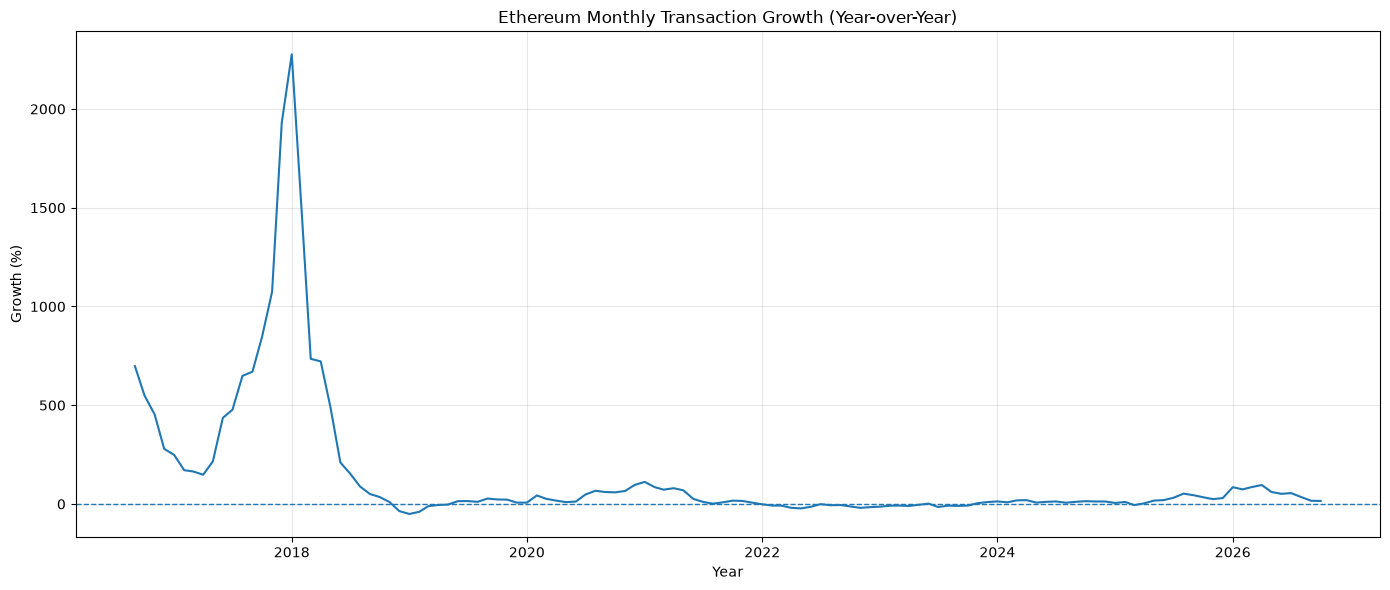

Chart saved: E:\DataScience\Ethereum_Monthly_TimeSeries_2015_2026\visualizations\03_yoy_transaction_growth.png


In [13]:
# Save year-over-year growth visualization

chart_file = visualizations_dir / "03_yoy_transaction_growth.png"

plt.figure(figsize=(14, 6))

plt.plot(
    analysis_df.index,
    analysis_df["yoy_growth_pct"],
    linewidth=1.5
)

plt.axhline(y=0, linestyle="--", linewidth=1)

plt.title("Ethereum Monthly Transaction Growth (Year-over-Year)")
plt.xlabel("Year")
plt.ylabel("Growth (%)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_file)

In [14]:
# Check monthly seasonality
# Average transaction count by calendar month

analysis_df["calendar_month"] = analysis_df.index.month

monthly_seasonality = (
    analysis_df.groupby("calendar_month")["tx_count"]
    .mean()
)

print("Average transactions by calendar month")
print("=" * 45)

for month, value in monthly_seasonality.items():
    print(f"{pd.Timestamp(2000, month, 1).strftime('%B'):12s} {value:,.0f}")

Average transactions by calendar month
January      29,062,381
February     25,877,227
March        28,848,904
April        28,998,318
May          30,958,410
June         29,542,462
July         31,506,092
August       31,851,545
September    26,757,350
October      27,418,932
November     24,803,770
December     26,944,419


In [15]:
# Calculate seasonal indices

overall_mean = analysis_df["tx_count"].mean()

seasonal_index = (monthly_seasonality / overall_mean) * 100

print("Seasonal indices (%)")
print("=" * 35)

for month, value in seasonal_index.items():
    month_name = pd.Timestamp(2000, month, 1).strftime("%B")
    print(f"{month_name:12s} {value:.2f}%")

Seasonal indices (%)
January      101.88%
February     90.72%
March        101.13%
April        101.66%
May          108.53%
June         103.56%
July         110.45%
August       111.66%
September    93.80%
October      96.12%
November     86.95%
December     94.46%


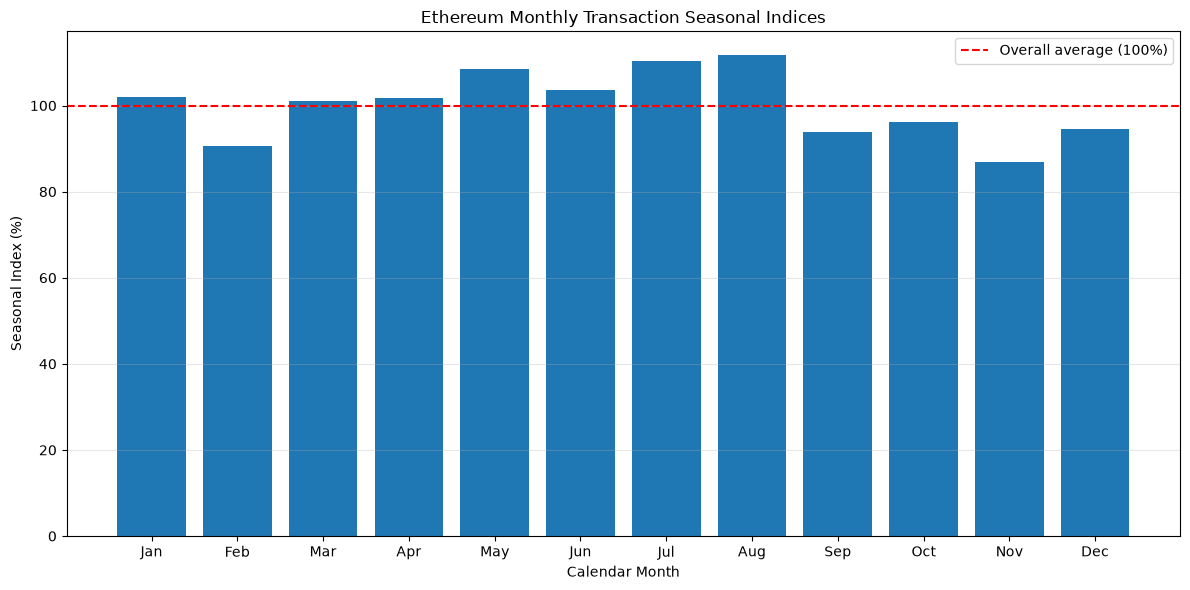

Chart saved: E:\DataScience\Ethereum_Monthly_TimeSeries_2015_2026\visualizations\04_monthly_seasonal_indices.png


In [16]:
# Plot seasonal indices

plt.figure(figsize=(12, 6))

month_labels = [
    pd.Timestamp(2000, month, 1).strftime("%b")
    for month in seasonal_index.index
]

plt.bar(month_labels, seasonal_index.values)

plt.axhline(
    y=100,
    color="red",
    linestyle="--",
    label="Overall average (100%)"
)

plt.title("Ethereum Monthly Transaction Seasonal Indices")
plt.xlabel("Calendar Month")
plt.ylabel("Seasonal Index (%)")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

chart_file = visualizations_dir / "04_monthly_seasonal_indices.png"
plt.savefig(chart_file, dpi=300, bbox_inches="tight")

plt.show()

print("Chart saved:", chart_file)

In [17]:
# Prepare the time series
# Prepare monthly time series for decomposition

ts = analysis_df["tx_count"].asfreq("MS")

print("Frequency:", ts.index.freq)
print("Observations:", len(ts))
print("Missing values:", ts.isna().sum())

Frequency: <MonthBegin>
Observations: 134
Missing values: 0


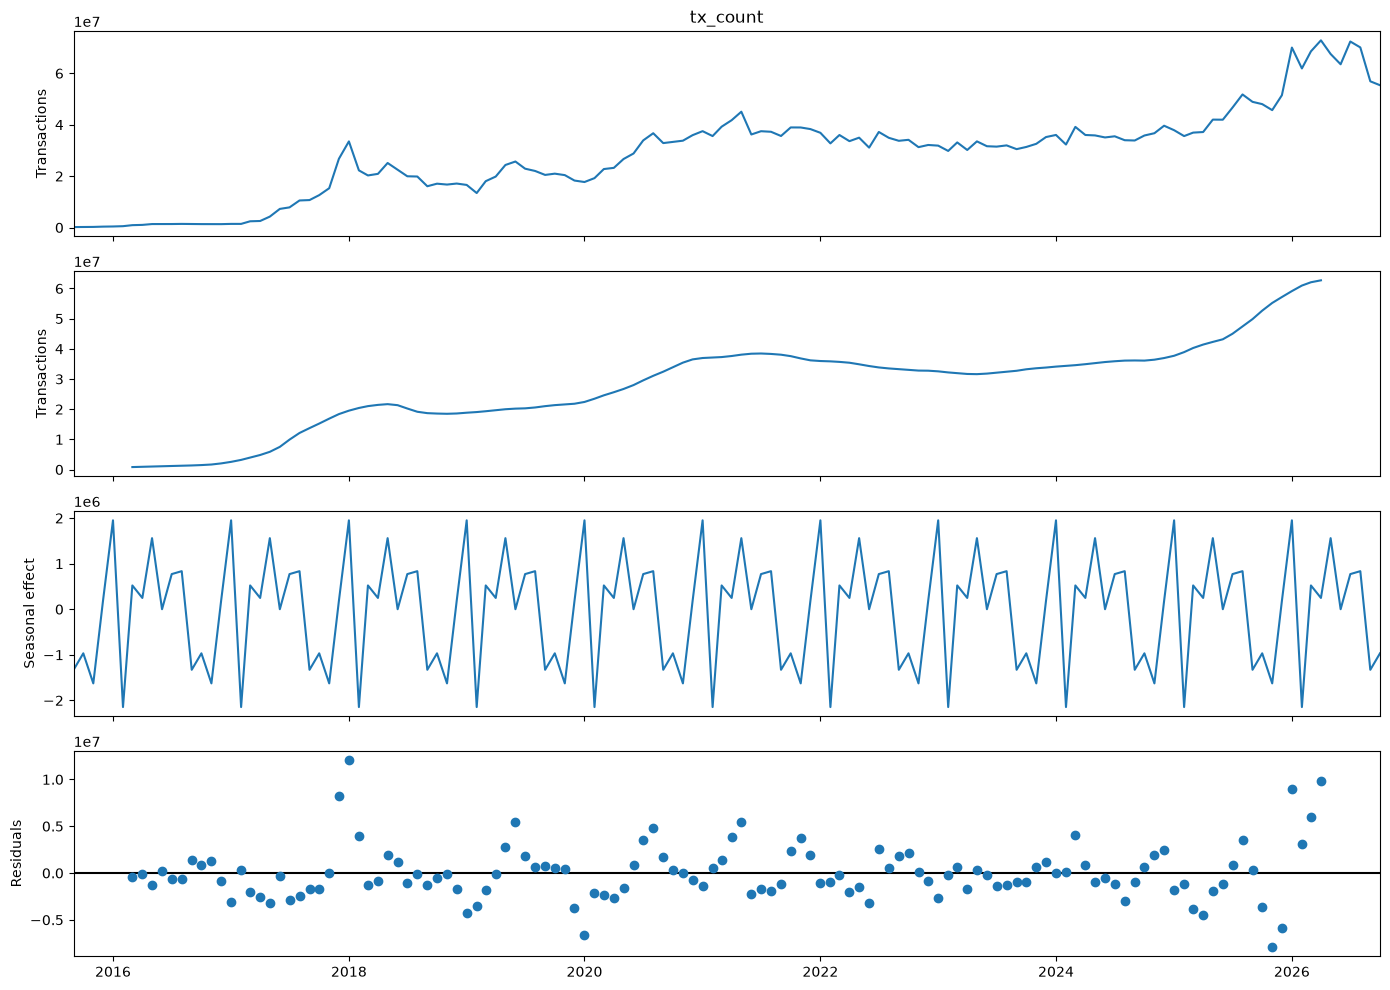

Decomposition chart saved: E:\DataScience\Ethereum_Monthly_TimeSeries_2015_2026\visualizations\05_time_series_decomposition.png


In [22]:
# Classical additive time-series decomposition
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    ts,
    model="additive",
    period=12
)

# Display decomposition components
fig = decomposition.plot()
fig.set_size_inches(14, 10)

axes = fig.axes
axes[0].set_ylabel("Transactions")
axes[1].set_ylabel("Transactions")
axes[2].set_ylabel("Seasonal effect")
axes[3].set_ylabel("Residuals")

plt.tight_layout()

# Save visualization
chart_file = visualizations_dir / "05_time_series_decomposition.png"
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("Decomposition chart saved:", chart_file)

In [23]:
## Stationarity Tests (ADF and KPSS)
# These tests help determine whether the Ethereum transaction-count time series
# is stationary, an important step before ARIMA/SARIMA forecasting
from statsmodels.tsa.stattools import adfuller, kpss

# Augmented Dickey-Fuller test
adf_result = adfuller(ts)

print("ADF TEST")
print("ADF statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical values:", adf_result[4])

print("\nKPSS TEST")
kpss_result = kpss(ts, regression="c", nlags="auto")

print("KPSS statistic:", kpss_result[0])
print("p-value:", kpss_result[1])
print("Critical values:", kpss_result[3])

ADF TEST
ADF statistic: -1.292412363598388
p-value: 0.6326364775549198
Critical values: {'1%': np.float64(-3.480500383888377), '5%': np.float64(-2.8835279559405045), '10%': np.float64(-2.578495716547007)}

KPSS TEST
KPSS statistic: 1.6523406722713785
p-value: 0.01
Critical values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}


C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_4704\2268445621.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(ts)
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_4704\2268445621.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(ts, regression="c", nlags="auto")
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_4704\2268445621.py:15: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store

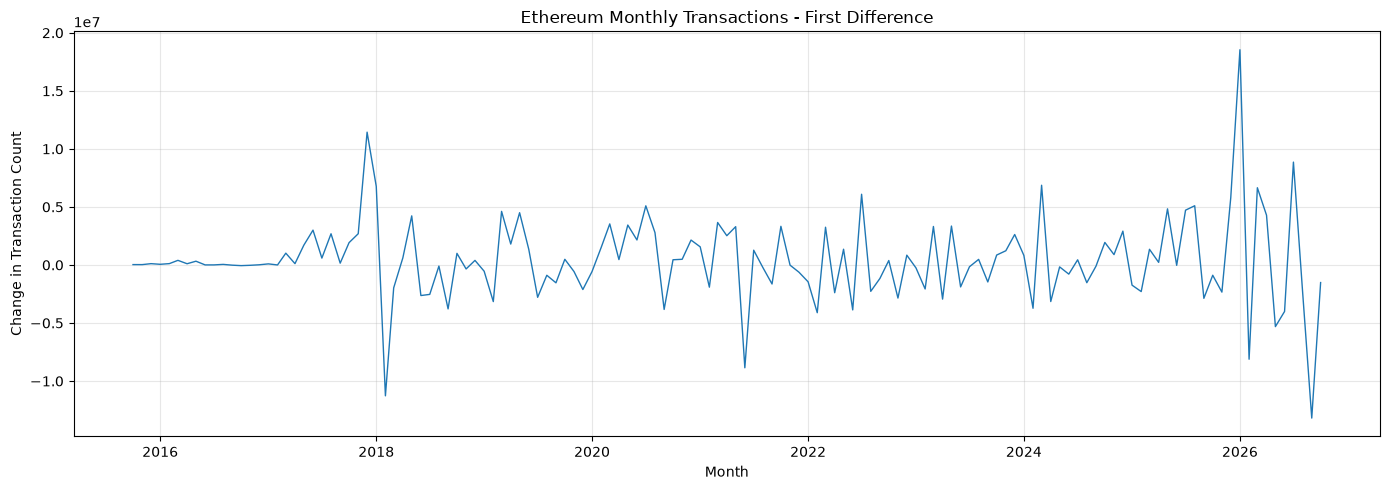

Observations: 133
Chart saved: E:\DataScience\Ethereum_Monthly_TimeSeries_2015_2026\visualizations\06_first_order_differencing.png


In [24]:
# First-order differencing
# First-order differencing
ts_diff = ts.diff().dropna()

# Plot differenced series
plt.figure(figsize=(14, 5))
plt.plot(ts_diff, linewidth=1)
plt.title("Ethereum Monthly Transactions - First Difference")
plt.xlabel("Month")
plt.ylabel("Change in Transaction Count")
plt.grid(True, alpha=0.3)
plt.tight_layout()

chart_file = visualizations_dir / "06_first_order_differencing.png"
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("Observations:", len(ts_diff))
print("Chart saved:", chart_file)

In [25]:
# ADF and KPSS tests on the differenced series
# ADF test
adf_diff = adfuller(ts_diff)

print("ADF TEST - FIRST DIFFERENCE")
print("ADF statistic:", adf_diff[0])
print("p-value:", adf_diff[1])

# KPSS test
kpss_diff = kpss(ts_diff, regression="c", nlags="auto")

print("\nKPSS TEST - FIRST DIFFERENCE")
print("KPSS statistic:", kpss_diff[0])
print("p-value:", kpss_diff[1])

ADF TEST - FIRST DIFFERENCE
ADF statistic: -9.599170365752368
p-value: 1.9413925864924454e-16

KPSS TEST - FIRST DIFFERENCE
KPSS statistic: 0.04369672781454338
p-value: 0.1


C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_4704\126162850.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff = adfuller(ts_diff)
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_4704\126162850.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_diff = kpss(ts_diff, regression="c", nlags="auto")
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_4704\126162850.py:10: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when st

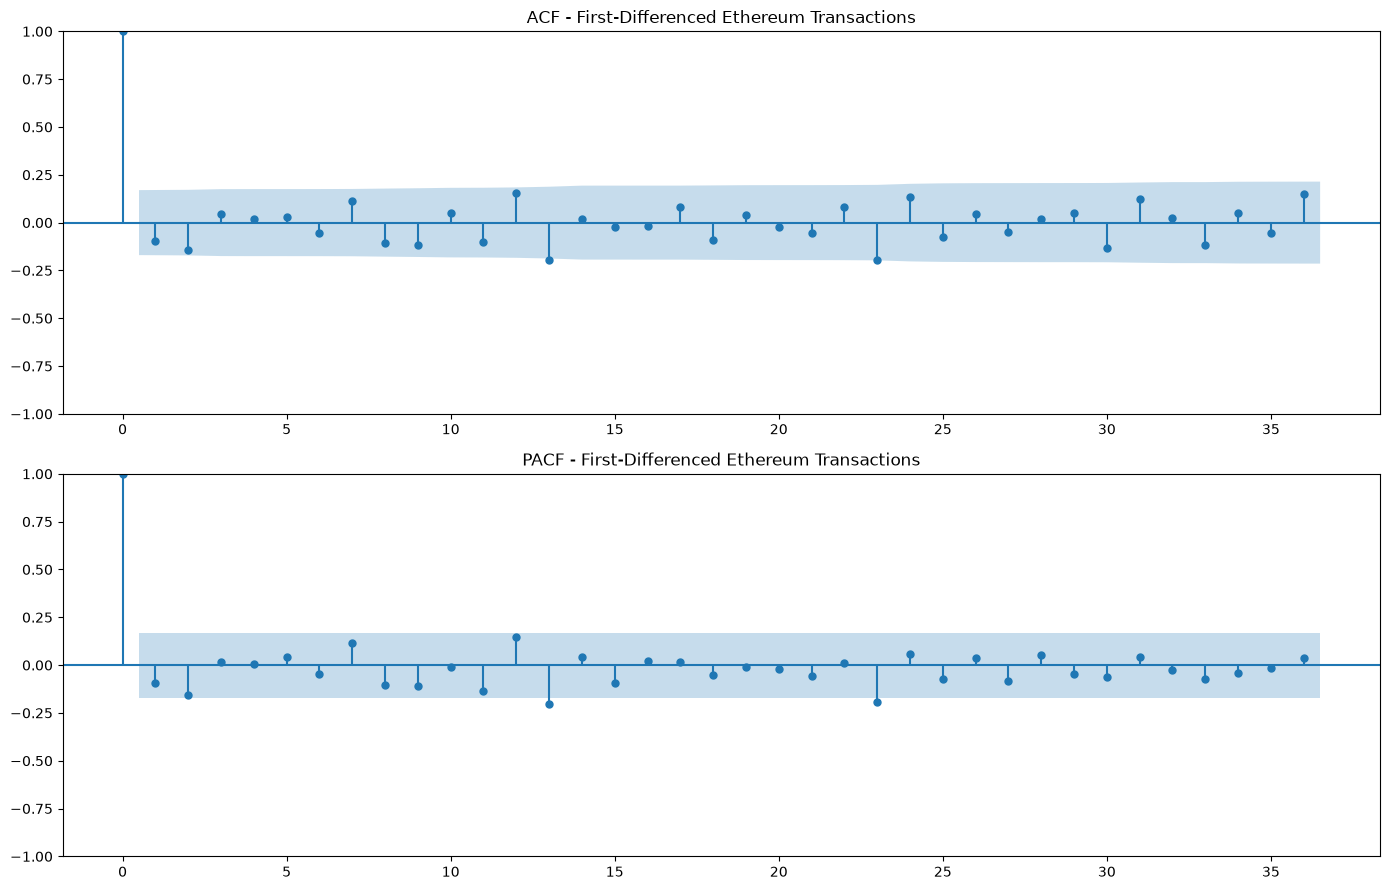

ACF/PACF chart saved: E:\DataScience\Ethereum_Monthly_TimeSeries_2015_2026\visualizations\07_acf_pacf_first_difference.png


In [26]:
# ACF and PACF
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

plot_acf(ts_diff, lags=36, ax=axes[0])
axes[0].set_title("ACF - First-Differenced Ethereum Transactions")

plot_pacf(ts_diff, lags=36, method="ywm", ax=axes[1])
axes[1].set_title("PACF - First-Differenced Ethereum Transactions")

plt.tight_layout()

chart_file = visualizations_dir / "07_acf_pacf_first_difference.png"
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("ACF/PACF chart saved:", chart_file)

In [27]:
# Numerical ACF and PACF values
from statsmodels.tsa.stattools import acf, pacf

acf_values = acf(ts_diff, nlags=36)
pacf_values = pacf(ts_diff, nlags=36, method="ywm")

acf_pacf_df = pd.DataFrame({
    "Lag": range(37),
    "ACF": acf_values,
    "PACF": pacf_values
})

print(acf_pacf_df.round(3).to_string(index=False))

 Lag    ACF   PACF
   0  1.000  1.000
   1 -0.095 -0.095
   2 -0.144 -0.155
   3  0.044  0.014
   4  0.020  0.004
   5  0.029  0.042
   6 -0.053 -0.044
   7  0.112  0.115
   8 -0.104 -0.103
   9 -0.118 -0.108
  10  0.052 -0.010
  11 -0.104 -0.133
  12  0.153  0.148
  13 -0.194 -0.203
  14  0.020  0.043
  15 -0.021 -0.093
  16 -0.017  0.023
  17  0.080  0.019
  18 -0.088 -0.052
  19  0.039 -0.008
  20 -0.025 -0.019
  21 -0.053 -0.058
  22  0.079  0.009
  23 -0.195 -0.191
  24  0.136  0.058
  25 -0.077 -0.071
  26  0.043  0.035
  27 -0.048 -0.085
  28  0.020  0.051
  29  0.051 -0.046
  30 -0.135 -0.060
  31  0.121  0.042
  32  0.025 -0.026
  33 -0.115 -0.074
  34  0.052 -0.041
  35 -0.052 -0.013
  36  0.151  0.035


In [28]:
# Log transformation and stationarity tests
# Log transformation
ts_log = np.log(ts)

# First-order differencing of log-transformed series
ts_log_diff = ts_log.diff().dropna()

# Stationarity tests
adf_log = adfuller(ts_log_diff)
kpss_log = kpss(ts_log_diff, regression="c", nlags="auto")

print("ADF TEST - LOG DIFFERENCED SERIES")
print("ADF statistic:", adf_log[0])
print("p-value:", adf_log[1])

print("\nKPSS TEST - LOG DIFFERENCED SERIES")
print("KPSS statistic:", kpss_log[0])
print("p-value:", kpss_log[1])

print("\nSTANDARD DEVIATION")
print("Original first difference:", ts_diff.std())
print("Log first difference:", ts_log_diff.std())

C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_4704\2788235037.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_log = adfuller(ts_log_diff)
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_4704\2788235037.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_log = kpss(ts_log_diff, regression="c", nlags="auto")
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_4704\2788235037.py:10: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags

ADF TEST - LOG DIFFERENCED SERIES
ADF statistic: -2.0877863037806916
p-value: 0.24945406619429572

KPSS TEST - LOG DIFFERENCED SERIES
KPSS statistic: 0.7695864096563233
p-value: 0.01

STANDARD DEVIATION
Original first difference: 3695033.929008786
Log first difference: 0.15054626595423845


In [29]:
## establish a baseline ARIMA model before testing more complex alternatives
# Fit ARIMA(1,1,1)
from statsmodels.tsa.arima.model import ARIMA

model_111 = ARIMA(ts, order=(1, 1, 1))
results_111 = model_111.fit()

print(results_111.summary())

                               SARIMAX Results                                
Dep. Variable:               tx_count   No. Observations:                  134
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -2199.497
Date:                Sun, 15 Nov 2026   AIC                           4404.995
Time:                        18:09:51   BIC                           4413.666
Sample:                    09-01-2015   HQIC                          4408.518
                         - 10-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3262      0.535      0.610      0.542      -0.722       1.374
ma.L1         -0.4378      0.503     -0.871      0.384      -1.423       0.547
sigma2      1.404e+13   1.93e-13   7.29e+25      0.0

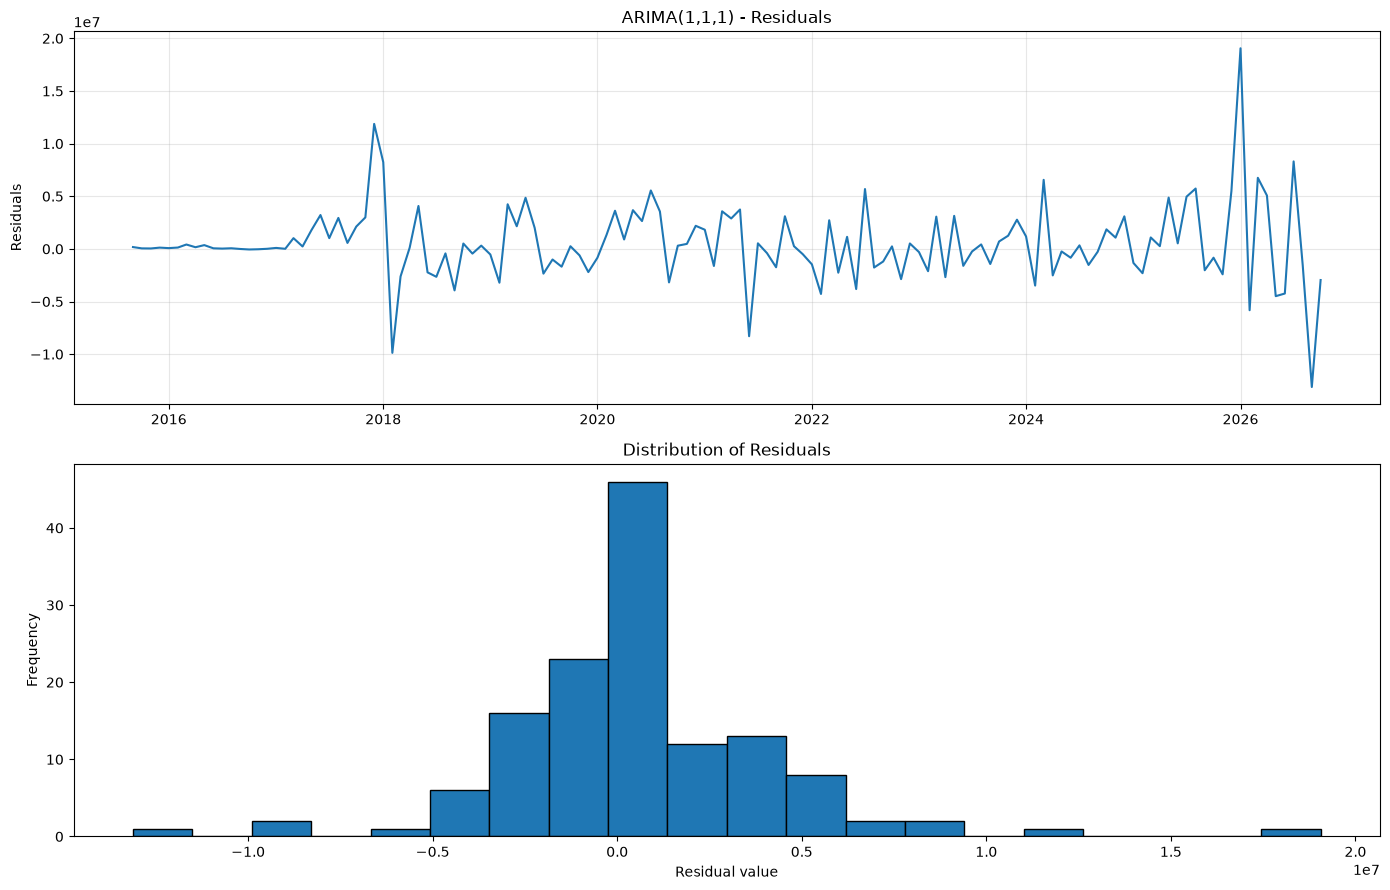

Residual diagnostics saved: E:\DataScience\Ethereum_Monthly_TimeSeries_2015_2026\visualizations\09_arima_111_residual_diagnostics.png


In [30]:
## Residual diagnostics
# Plot model residuals
residuals = results_111.resid

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(residuals)
axes[0].set_title("ARIMA(1,1,1) - Residuals")
axes[0].set_ylabel("Residuals")
axes[0].grid(True, alpha=0.3)

axes[1].hist(residuals, bins=20, edgecolor="black")
axes[1].set_title("Distribution of Residuals")
axes[1].set_xlabel("Residual value")
axes[1].set_ylabel("Frequency")

plt.tight_layout()

chart_file = visualizations_dir / "09_arima_111_residual_diagnostics.png"
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("Residual diagnostics saved:", chart_file)

In [31]:
# Residual autocorrelation test
from statsmodels.stats.diagnostic import acorr_ljungbox

ljung_box_results = acorr_ljungbox(
    residuals,
    lags=[12, 24],
    return_df=True
)

print("LJUNG-BOX RESIDUAL TEST")
print(ljung_box_results.round(4))

LJUNG-BOX RESIDUAL TEST
    lb_stat  lb_pvalue
12  11.6608     0.4733
24  27.6530     0.2749


In [32]:
## Compare three ARIMA models
# Fit three candidate models
from statsmodels.tsa.arima.model import ARIMA

candidate_orders = [
    (0, 1, 1),
    (1, 1, 0),
    (1, 1, 1)
]

model_comparison = []

for order in candidate_orders:
    model = ARIMA(ts, order=order)
    fitted_model = model.fit()

    model_comparison.append({
        "Model": f"ARIMA{order}",
        "AIC": fitted_model.aic,
        "BIC": fitted_model.bic,
        "Log_Likelihood": fitted_model.llf
    })

comparison_df = pd.DataFrame(model_comparison)

print(comparison_df.round(3).to_string(index=False))

         Model      AIC      BIC  Log_Likelihood
ARIMA(0, 1, 1) 4403.611 4409.392       -2199.805
ARIMA(1, 1, 0) 4403.839 4409.620       -2199.919
ARIMA(1, 1, 1) 4404.995 4413.666       -2199.497


In [33]:
# Fit the ARIMA(0,1,1) model
model_011 = ARIMA(ts, order=(0, 1, 1))
results_011 = model_011.fit()

print(results_011.summary())

                               SARIMAX Results                                
Dep. Variable:               tx_count   No. Observations:                  134
Model:                 ARIMA(0, 1, 1)   Log Likelihood               -2199.805
Date:                Sun, 15 Nov 2026   AIC                           4403.611
Time:                        18:15:09   BIC                           4409.392
Sample:                    09-01-2015   HQIC                          4405.960
                         - 10-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.1069      0.059     -1.823      0.068      -0.222       0.008
sigma2      1.405e+13   1.05e-15   1.33e+28      0.000     1.4e+13     1.4e+13
Ljung-Box (L1) (Q):                   0.00   Jarque-

In [34]:
## investigate seasonality
# Seasonal differencing (12 months)
# Seasonal differencing
ts_seasonal_diff = ts.diff(12).dropna()

# Stationarity tests
adf_seasonal = adfuller(ts_seasonal_diff)
kpss_seasonal = kpss(
    ts_seasonal_diff,
    regression="c",
    nlags="auto"
)

print("SEASONAL DIFFERENCING - 12 MONTHS")
print("Observations:", len(ts_seasonal_diff))

print("\nADF TEST")
print("ADF statistic:", adf_seasonal[0])
print("p-value:", adf_seasonal[1])

print("\nKPSS TEST")
print("KPSS statistic:", kpss_seasonal[0])
print("p-value:", kpss_seasonal[1])

SEASONAL DIFFERENCING - 12 MONTHS
Observations: 122

ADF TEST
ADF statistic: -2.251111163680679
p-value: 0.18822041296795716

KPSS TEST
KPSS statistic: 0.17197228977256393
p-value: 0.1


C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_4704\3901699605.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_seasonal = adfuller(ts_seasonal_diff)
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_4704\3901699605.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_seasonal = kpss(
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_4704\3901699605.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In releas

In [35]:
# Combined differencing (the combination of ordinary and seasonal differencing)
# First-order and seasonal differencing
ts_combined_diff = ts.diff().diff(12).dropna()

# Stationarity tests
adf_combined = adfuller(ts_combined_diff)
kpss_combined = kpss(
    ts_combined_diff,
    regression="c",
    nlags="auto"
)

print("COMBINED DIFFERENCING")
print("Observations:", len(ts_combined_diff))

print("\nADF TEST")
print("ADF statistic:", adf_combined[0])
print("p-value:", adf_combined[1])

print("\nKPSS TEST")
print("KPSS statistic:", kpss_combined[0])
print("p-value:", kpss_combined[1])

COMBINED DIFFERENCING
Observations: 121

ADF TEST
ADF statistic: -4.43042766197793
p-value: 0.0002621131272166875

KPSS TEST
KPSS statistic: 0.04098010436889058
p-value: 0.1


C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_4704\3210778041.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_combined = adfuller(ts_combined_diff)
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_4704\3210778041.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_combined = kpss(
C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_4704\3210778041.py:7: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In releas

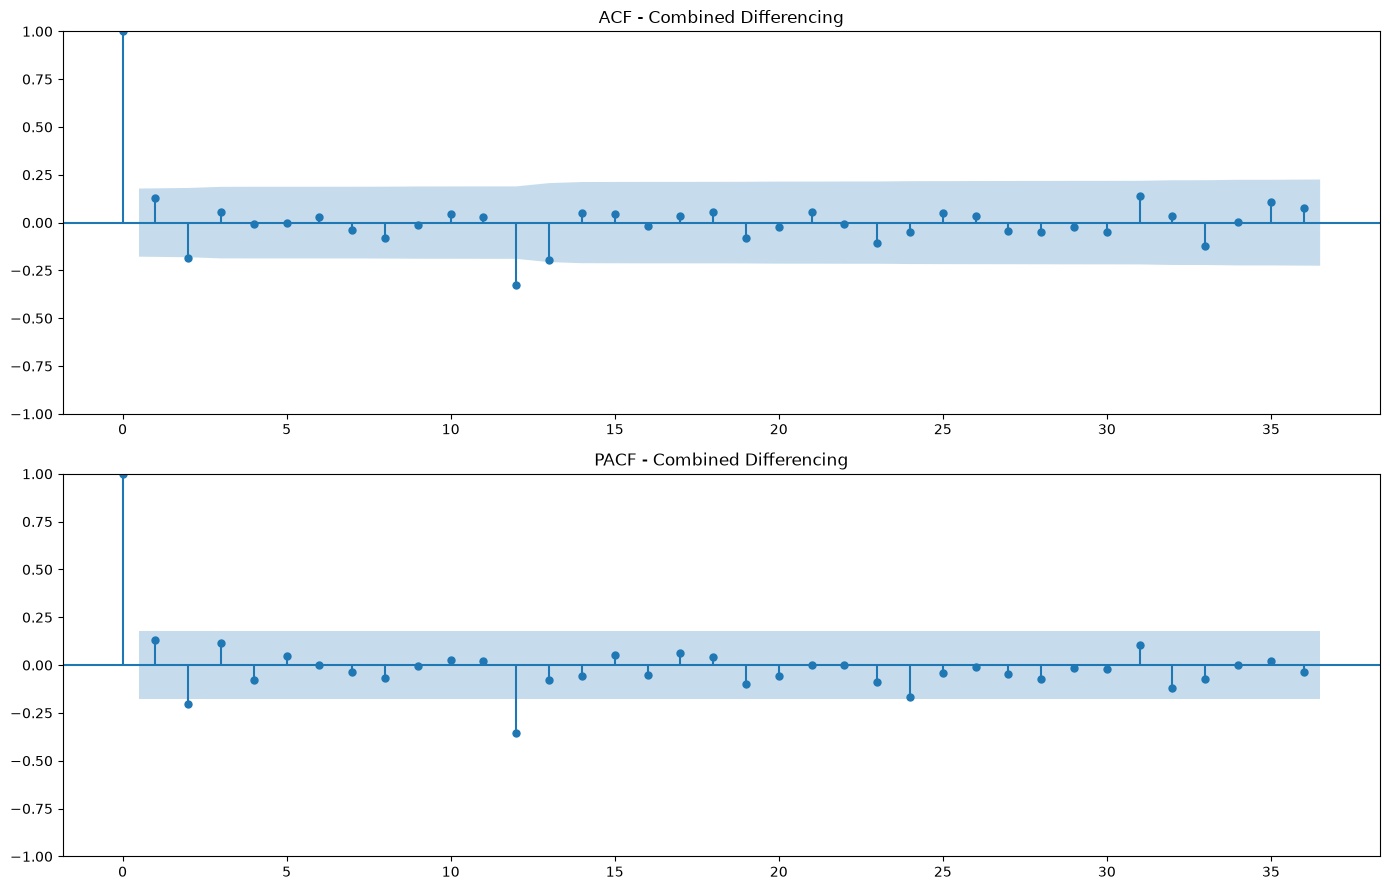

Chart saved: E:\DataScience\Ethereum_Monthly_TimeSeries_2015_2026\visualizations\10_acf_pacf_combined_differencing.png


In [36]:
# ACF and PACF after combined differencing
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

plot_acf(ts_combined_diff, lags=36, ax=axes[0])
axes[0].set_title("ACF - Combined Differencing")

plot_pacf(ts_combined_diff, lags=36, method="ywm", ax=axes[1])
axes[1].set_title("PACF - Combined Differencing")

plt.tight_layout()

chart_file = visualizations_dir / "10_acf_pacf_combined_differencing.png"
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_file)

In [37]:
# Numerical ACF/PACF after combined differencing
from statsmodels.tsa.stattools import acf, pacf

acf_combined = acf(ts_combined_diff, nlags=36)
pacf_combined = pacf(
    ts_combined_diff,
    nlags=36,
    method="ywm"
)

combined_acf_pacf_df = pd.DataFrame({
    "Lag": range(37),
    "ACF": acf_combined,
    "PACF": pacf_combined
})

print(combined_acf_pacf_df.round(3).to_string(index=False))

 Lag    ACF   PACF
   0  1.000  1.000
   1  0.130  0.130
   2 -0.184 -0.205
   3  0.053  0.115
   4 -0.005 -0.076
   5 -0.003  0.048
   6  0.028 -0.002
   7 -0.040 -0.035
   8 -0.081 -0.069
   9 -0.013 -0.006
  10  0.043  0.026
  11  0.027  0.022
  12 -0.326 -0.353
  13 -0.194 -0.078
  14  0.048 -0.058
  15  0.044  0.053
  16 -0.019 -0.053
  17  0.036  0.063
  18  0.054  0.043
  19 -0.082 -0.101
  20 -0.020 -0.055
  21  0.053  0.003
  22 -0.005 -0.001
  23 -0.105 -0.087
  24 -0.048 -0.167
  25  0.050 -0.039
  26  0.035 -0.012
  27 -0.042 -0.045
  28 -0.049 -0.071
  29 -0.024 -0.015
  30 -0.051 -0.020
  31  0.141  0.107
  32  0.035 -0.118
  33 -0.122 -0.073
  34  0.003  0.002
  35  0.106  0.021
  36  0.079 -0.037


In [38]:
# Fit a preliminary SARIMA model
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_011_011 = SARIMAX(
    ts,
    order=(0, 1, 1),
    seasonal_order=(0, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

results_sarima = sarima_011_011.fit(disp=False)

print(results_sarima.summary())

                                     SARIMAX Results                                      
Dep. Variable:                           tx_count   No. Observations:                  134
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood               -1774.809
Date:                            Sun, 15 Nov 2026   AIC                           3555.618
Time:                                    18:22:37   BIC                           3563.636
Sample:                                09-01-2015   HQIC                          3558.869
                                     - 10-01-2026                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.0549      0.095      0.578      0.564      -0.131       0.241
ma.S.L12      -0.8020      0.143   